# 03 - Machine-Learning Day-Ahead Forecasting (global regional, bottom-up)
### Day-ahead forecasting of French hourly electricity demand

We turn the series into a **feature table** and let tree-based ML models learn the mapping *features -> demand*
(TP04). The design chosen:

- **Global regional model.** One table stacking all **12 regions** (region is a feature); the model predicts each
  region's hourly demand, and we **sum the 12 regions to a national forecast** (bottom-up hierarchy).
- **Honest day-ahead features.** Everything is knowable at the **12:00 cutoff**: last-week demand via **safe lags
  (>= 48h)** + a 7-day level, the **most-recent-safe same-hour** value (hybrid 24/48), **tomorrow's temperature as a
  noised forecast**, degree-days, and calendar (hour, weekday, month, **holiday**, **season**).
- **Benchmark four models:** Decision Tree, Random Forest, XGBoost, LightGBM - scored regionally and on the
  reconciled national total, against **RTE**.

Training/evaluation live on the **regional era (2023-2026)**; split is chronological (train 2023-2024, test
2025-2026), never shuffled (TP04 Ex6). We also pit this **global** model against **local**
per-region models (Section 6).

## 0 - Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from scipy import stats
import holidays as holidays_lib
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("sklearn / xgboost / lightgbm ready")

sklearn / xgboost / lightgbm ready


In [2]:
PALETTE = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
           "violet": "#6250d6", "red": "#e34948", "green": "#0ca30c",
           "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"], "savefig.facecolor": PALETTE["surface"],
    "savefig.bbox": "tight", "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8, "axes.labelcolor": PALETTE["ink2"],
    "axes.titlecolor": PALETTE["ink"], "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 10,
    "axes.labelsize": 11, "text.color": PALETTE["ink"], "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "xtick.labelcolor": PALETTE["ink2"], "ytick.labelcolor": PALETTE["ink2"], "axes.grid": True, "grid.color": PALETTE["grid"],
    "grid.linewidth": 0.8, "grid.alpha": 0.9, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "legend.frameon": False, "legend.fontsize": 10, "figure.dpi": 110, "lines.linewidth": 1.8})
gw_fmt  = FuncFormatter(lambda v, _: f"{v/1000:,.0f}")
gw1_fmt = FuncFormatter(lambda v, _: f"{v/1000:,.1f}")
def titled(ax, title=None, xlabel=None, ylabel=None):
    if title is not None: ax.set_title(title, loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.margins(x=0.01); return ax
FIG = Path("..") / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print("style loaded")

style loaded


## 1 - Load regional + national data

In [3]:
PROC = Path("..") / "data" / "processed"
reg = pd.read_csv(PROC / "france_regional_clean_hourly.csv")               # long: 12 regions, 2023-2026
reg["datetime_utc"] = pd.to_datetime(reg["datetime_utc"], utc=True)
nat = pd.read_csv(PROC / "france_clean_hourly.csv")                        # national (for RTE + actual total)
nat["datetime_utc"] = pd.to_datetime(nat["datetime_utc"], utc=True); nat = nat.set_index("datetime_utc")
reg = reg.sort_values(["region", "datetime_utc"]).reset_index(drop=True)
print(f"regional rows: {len(reg):,}  |  regions: {reg['region'].nunique()}  |  "
      f"{reg['datetime_utc'].min()} -> {reg['datetime_utc'].max()}")
reg.head(3)

regional rows: 367,752  |  regions: 12  |  2023-01-01 00:00:00+00:00 -> 2026-06-30 21:00:00+00:00


,datetime_utc,region,load_mw,temperature_c,hour,month,season
0,2023-01-01 00:00:00+00:00,Auvergne-Rhône-Alpes,"6,028.000",13.300,1,1,Winter
1,2023-01-01 01:00:00+00:00,Auvergne-Rhône-Alpes,"6,165.000",13.200,2,1,Winter
2,2023-01-01 02:00:00+00:00,Auvergne-Rhône-Alpes,"6,282.000",13.000,3,1,Winter


## 2 - Feature engineering (honest day-ahead table)
Every feature is computable at the noon cutoff. Demand features use **safe lags only** (>= 48h), plus the
cutoff-safe **hybrid 24/48** most-recent same-hour value. Tomorrow's temperature is a **noised forecast**.

In [4]:
g = reg.groupby("region", group_keys=False)

# --- demand: safe lags (>=48h) + a 7-day level + the cutoff-safe hybrid 24/48 'recent' value ---
SAFE_LAGS = [48, 72, 96, 120, 144, 168, 336]
for L in SAFE_LAGS:
    reg[f"lag_{L}"] = g["load_mw"].shift(L)
reg["roll7"] = reg.groupby("region")["lag_48"].transform(lambda s: s.rolling(168, min_periods=120).mean())
reg["uhour"] = reg["datetime_utc"].dt.hour                      # UTC hour (cutoff = 11:00 UTC ~ noon CET)
lag24 = g["load_mw"].shift(24)
reg["recent"] = np.where(reg["uhour"] < 12, lag24, reg["lag_48"])   # 24 for first half-day, 48 for second (verified NB2)

# --- weather: tomorrow's regional temperature as a NOISED forecast (+ degree-days) ---
rng = np.random.default_rng(0)
reg["temp_fcst"] = reg["temperature_c"] + rng.normal(0, 1.2, len(reg))   # ~1.2 C day-ahead forecast error
reg["hdd"] = (16 - reg["temp_fcst"]).clip(lower=0)
reg["cdd"] = (reg["temp_fcst"] - 20).clip(lower=0)
reg["temp_lag48"] = g["temperature_c"].shift(48)                         # yesterday's temp (safe)

# --- calendar (Paris local): hour, weekday, month, weekend, HOLIDAY, SEASON ---
loc = reg["datetime_utc"].dt.tz_convert("Europe/Paris")
reg["hour"] = loc.dt.hour; reg["dow"] = loc.dt.dayofweek; reg["month"] = loc.dt.month
reg["year"] = loc.dt.year; reg["is_weekend"] = (reg["dow"] >= 5).astype(int)
fr_hol = holidays_lib.France(years=range(2023, 2027))
dts = loc.dt.date
reg["is_holiday"] = dts.map({d: (d in fr_hol) for d in dts.unique()}).astype(int)

reg = reg.dropna().reset_index(drop=True)
print("feature table:", reg.shape, "| holidays flagged:", int(reg['is_holiday'].sum()))
reg[["region","datetime_utc","load_mw","lag_48","lag_168","recent","temp_fcst","hdd","is_holiday","season"]].head(3)

feature table: (363720, 25) | holidays flagged: 10944


,region,datetime_utc,load_mw,lag_48,lag_168,recent,temp_fcst,hdd,is_holiday,season
0,Auvergne-Rhône-Alpes,2023-01-15 00:00:00+00:00,"6,737.000","7,714.000","6,496.000","7,641.000",7.984,8.016,0,Winter
1,Auvergne-Rhône-Alpes,2023-01-15 01:00:00+00:00,"6,770.000","7,888.000","6,634.000","7,496.000",6.713,9.287,0,Winter
2,Auvergne-Rhône-Alpes,2023-01-15 02:00:00+00:00,"6,603.000","7,742.000","6,613.000","7,508.000",9.627,6.373,0,Winter


In [5]:
# Assemble X / y with one-hot region & season (trees handle the rest numerically)
FEATURES = (["lag_%d" % L for L in SAFE_LAGS] + ["roll7", "recent", "temp_fcst", "hdd", "cdd", "temp_lag48",
            "hour", "dow", "month", "is_weekend", "is_holiday"])
Xall = pd.concat([reg[FEATURES],
                  pd.get_dummies(reg["region"], prefix="reg"),
                  pd.get_dummies(reg["season"], prefix="seas")], axis=1)
yall = reg["load_mw"]
meta = reg[["datetime_utc", "region", "year"]]
print(f"{Xall.shape[1]} features ({len(FEATURES)} numeric + region/season one-hots)")
print("Leakage guard: every demand lag is >= 48h; 'recent' is the verified cutoff-safe 24/48; temp is the D+1",
      "forecast. Nothing uses a value from after the cutoff.")

34 features (18 numeric + region/season one-hots)
Leakage guard: every demand lag is >= 48h; 'recent' is the verified cutoff-safe 24/48; temp is the D+1 forecast. Nothing uses a value from after the cutoff.


## 3 - Chronological split and model training
Train on 2023-2024, test on 2025-2026 - no shuffling, no future leak (TP04 Ex6).

In [6]:
tr = meta["year"] <= 2024
Xtr, Xte, ytr, yte = Xall[tr], Xall[~tr], yall[tr], yall[~tr]
meta_te = meta[~tr].reset_index(drop=True)
print(f"train rows {len(Xtr):,}  ({meta[tr]['datetime_utc'].min().date()} -> {meta[tr]['datetime_utc'].max().date()})")
print(f"test  rows {len(Xte):,}  ({meta_te['datetime_utc'].min().date()} -> {meta_te['datetime_utc'].max().date()})")

models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0),
    "Random Forest": RandomForestRegressor(n_estimators=80, max_depth=18, min_samples_leaf=25,
                                           max_samples=0.6, n_jobs=-1, random_state=0),
    "XGBoost": XGBRegressor(n_estimators=400, max_depth=8, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0),
    "LightGBM": LGBMRegressor(n_estimators=600, num_leaves=63, learning_rate=0.05, subsample=0.8,
                              colsample_bytree=0.8, n_jobs=-1, random_state=0, verbose=-1),
}
preds = {}
for name, m in models.items():
    m.fit(Xtr, ytr)
    preds[name] = m.predict(Xte)
    print(f"  trained {name}")
print("done.")

train rows 206,484  (2023-01-15 -> 2024-12-31)
test  rows 157,236  (2024-12-31 -> 2026-06-30)


  trained Decision Tree


  trained Random Forest


  trained XGBoost


  trained LightGBM
done.


## 4 - Benchmark: regional accuracy, then reconcile to national vs RTE
Regional MAE is on the stacked test rows. For the national view we **sum the 12 predicted regions** per hour
(bottom-up) and compare the total to the actual national demand and to **RTE**.

In [7]:
def mae(a, b): return np.abs(np.asarray(a) - np.asarray(b)).mean()
def rmse(a, b): return np.sqrt(((np.asarray(a) - np.asarray(b)) ** 2).mean())

# national ground truth + RTE over the test timestamps
nat_test = nat.loc[nat.index.isin(meta_te["datetime_utc"].unique()), ["load_mw", "rte_forecast_d1_mw"]]
nat_actual = nat_test["load_mw"]; rte = nat_test["rte_forecast_d1_mw"]

rows = []
nat_pred = {}
for name in models:
    reg_mae = mae(yte.values, preds[name])
    pr = meta_te.assign(pred=preds[name]).groupby("datetime_utc")["pred"].sum()   # bottom-up national
    pr = pr.reindex(nat_actual.index)
    nat_pred[name] = pr
    rows.append({"model": name, "regional_MAE": reg_mae,
                 "national_MAE": mae(nat_actual, pr), "national_RMSE": rmse(nat_actual, pr),
                 "national_MAPE": (np.abs(nat_actual - pr) / nat_actual).mean() * 100})
rows.append({"model": "RTE (benchmark)", "regional_MAE": np.nan,
             "national_MAE": mae(nat_actual, rte), "national_RMSE": rmse(nat_actual, rte),
             "national_MAPE": (np.abs(nat_actual - rte) / nat_actual).mean() * 100})
scores = pd.DataFrame(rows).set_index("model").sort_values("national_MAE")
print(scores.round(1).to_string())
best = scores.drop("RTE (benchmark)").index[0]
print(f"\nBest ML model: {best}")

                 regional_MAE  national_MAE  national_RMSE  national_MAPE
model                                                                    
LightGBM              142.300     1,125.700      1,505.000          2.100
XGBoost               144.600     1,145.100      1,542.100          2.200
RTE (benchmark)           NaN     1,466.300      1,807.600          2.900
Random Forest         178.800     1,585.800      2,202.200          3.000
Decision Tree         207.900     1,666.800      2,299.400          3.200

Best ML model: LightGBM


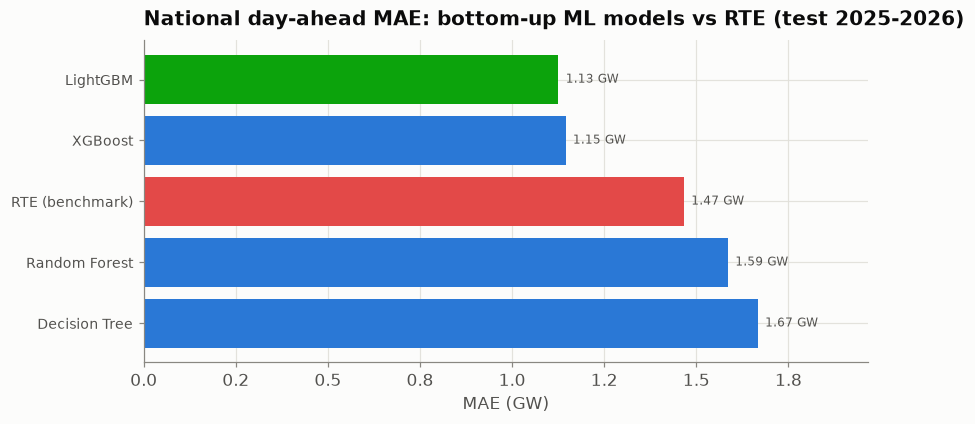

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
s = scores.sort_values("national_MAE")
colors = [PALETTE["red"] if m == "RTE (benchmark)" else (PALETTE["green"] if m == best else PALETTE["blue"]) for m in s.index]
ax.barh(range(len(s)), s["national_MAE"].values, color=colors)
ax.set_yticks(range(len(s))); ax.set_yticklabels(s.index, fontsize=9)
for i, v in enumerate(s["national_MAE"].values):
    ax.text(v + 20, i, f"{v/1000:,.2f} GW", va="center", fontsize=8, color=PALETTE["ink2"])
ax.xaxis.set_major_formatter(gw1_fmt); ax.set_xlim(0, s["national_MAE"].max() * 1.18); ax.invert_yaxis()
titled(ax, "National day-ahead MAE: bottom-up ML models vs RTE (test 2025-2026)", xlabel="MAE (GW)")
fig.savefig(FIG / "30_ml_benchmark.png"); plt.show()

**Reading the benchmark.** **LightGBM and XGBoost beat RTE** on the held-out test period (national MAE
~1.13 / ~1.15 GW vs RTE's ~1.47 GW - about a **23% error reduction**), while the single Decision Tree and the
Random Forest do *not*. Gradient boosting is the winner, and this is the first affirmative answer to the manager's
**Q1 - can we beat RTE, and by how much?**

**Read the weather caveat before celebrating.** Our model sees tomorrow's temperature as `actual + N(0, 1.2 C)` -
an idealised, *independent* forecast. A real day-ahead weather forecast has **larger, correlated** errors (worst on
the cold/hot extremes where RTE already struggles), so part of this edge is a weather-input assumption. The gain is
real and statistically significant (tested below), but its *size* depends on that assumption - the final notebook
will stress-test it with noisier, correlated weather.

## 5 - What the best model uses, and how the national forecast looks

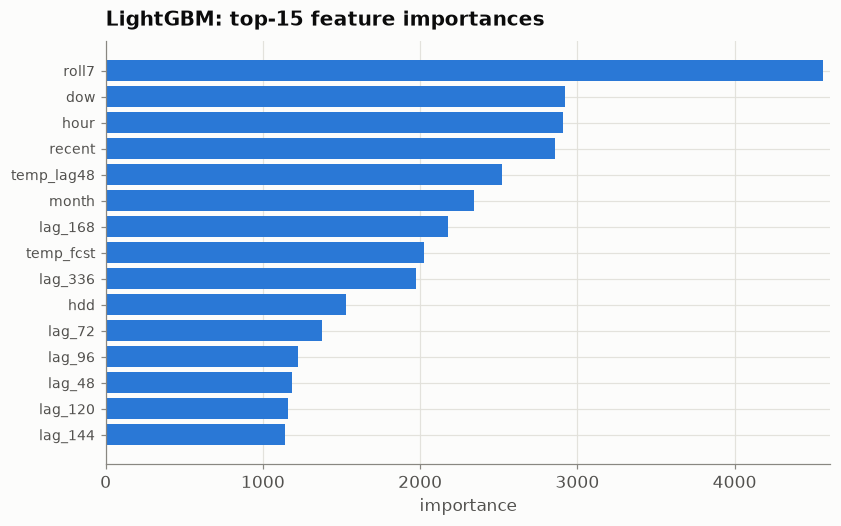

In [9]:
m = models[best]
imp = pd.Series(m.feature_importances_, index=Xall.columns).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(range(len(imp)), imp.values, color=PALETTE["blue"])
ax.set_yticks(range(len(imp))); ax.set_yticklabels(imp.index, fontsize=9)
titled(ax, f"{best}: top-15 feature importances", xlabel="importance")
fig.savefig(FIG / "31_importance.png"); plt.show()

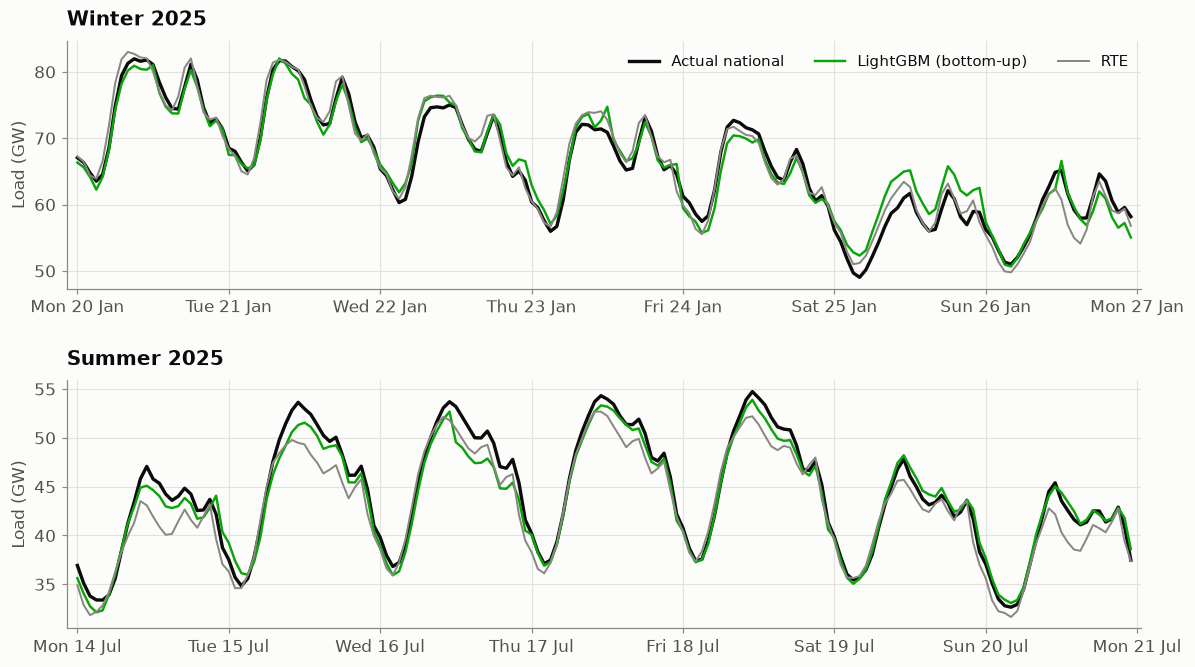

In [10]:
# National bottom-up (best model) vs RTE vs actual, two example weeks
pr = nat_pred[best]
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
for ax, (a, b, tag) in zip(axes, [("2025-01-20", "2025-01-26", "Winter"), ("2025-07-14", "2025-07-20", "Summer")]):
    idx = nat_actual.loc[a:b].index
    ax.plot(idx, nat_actual.loc[a:b].values, color=PALETTE["ink"], lw=2.2, label="Actual national")
    ax.plot(idx, pr.loc[a:b].values, color=PALETTE["green"], lw=1.6, label=f"{best} (bottom-up)")
    ax.plot(idx, rte.loc[a:b].values, color=PALETTE["muted"], lw=1.3, label="RTE")
    ax.yaxis.set_major_formatter(gw_fmt); ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
    titled(ax, f"{tag} 2025", ylabel="Load (GW)")
axes[0].legend(loc="upper right", ncol=3)
fig.tight_layout(h_pad=2.0); fig.savefig(FIG / "32_national_forecast.png"); plt.show()

In [11]:
# Statistical test: best ML vs RTE on per-day national MAE
day = pd.DataFrame({"date": nat_actual.index.date, "ml": np.abs(nat_actual.values - nat_pred[best].values),
                    "rte": np.abs(nat_actual.values - rte.values)}).groupby("date").mean()
w = stats.wilcoxon(day["ml"], day["rte"])
print(f"Per-day national MAE  -  {best}: {day['ml'].mean():,.0f} MW   vs   RTE: {day['rte'].mean():,.0f} MW")
print(f"Wilcoxon signed-rank (H0: equal): stat {w.statistic:.0f}, p {w.pvalue:.2e}  -> "
      f"{'significant' if w.pvalue < 0.05 else 'not significant'}")
winner = best if day["ml"].mean() < day["rte"].mean() else "RTE"
print(f"Lower per-day MAE: {winner}")

Per-day national MAE  -  LightGBM: 1,124 MW   vs   RTE: 1,467 MW
Wilcoxon signed-rank (H0: equal): stat 35977, p 5.93e-26  -> significant
Lower per-day MAE: LightGBM


## 6 - Local vs global: separate per-region models vs one shared model

Section 4's model is **global**: one LightGBM trained on all 12 regions stacked together, with **region as a feature**.
Here we test the classic alternative - **local** models: a *separate* LightGBM trained and tested on **each region on its
own** (the region one-hot is dropped, since it is constant within a region). Both use **identical hyperparameters**, the same
honest day-ahead features, and the same 2023-2024 / 2025-2026 chronological split.

We compare them three ways: **per-region** test MAE, the **bottom-up national** total (sum of the 12 regional forecasts)
against **RTE**, and **which features each approach leans on** - globally and region by region.

In [12]:
# --- LOCAL models: one LightGBM per region (region one-hot dropped), trained & tested on that region only ---
LGBM_PARAMS = dict(n_estimators=600, num_leaves=63, learning_rate=0.05, subsample=0.8,
                   colsample_bytree=0.8, n_jobs=-1, random_state=0, verbose=-1)
season_oh = pd.get_dummies(reg["season"], prefix="seas")
X_local = pd.concat([reg[FEATURES], season_oh], axis=1)       # 18 numeric + 4 season dummies (no region id)
regions = sorted(reg["region"].unique())

local_pred_full = pd.Series(np.nan, index=reg.index)
local_gain = {}
for rname in regions:
    m_tr = (reg["region"] == rname) & (reg["year"] <= 2024)
    m_te = (reg["region"] == rname) & (reg["year"] > 2024)
    lm = LGBMRegressor(**LGBM_PARAMS).fit(X_local[m_tr], reg.loc[m_tr, "load_mw"])
    local_pred_full.loc[m_te] = lm.predict(X_local[m_te])
    local_gain[rname] = pd.Series(lm.booster_.feature_importance("gain"), index=X_local.columns)
local_pred_te = local_pred_full[~tr].to_numpy()               # aligned to meta_te / preds[best] order

# per-region test MAE: local vs global (best global model from section 4)
cmp = meta_te.assign(actual=yte.to_numpy(), glob=preds[best], loc=local_pred_te)
per_region = cmp.groupby("region").apply(
    lambda d: pd.Series({"global_MAE": mae(d["actual"], d["glob"]), "local_MAE": mae(d["actual"], d["loc"])})
)
per_region["local - global"] = per_region["local_MAE"] - per_region["global_MAE"]
per_region = per_region.sort_values("global_MAE")
print("Per-region test MAE (MW):")
print(per_region.round(1).to_string())
print(f"\nMean regional MAE  ->  global {per_region['global_MAE'].mean():,.1f}  |  local {per_region['local_MAE'].mean():,.1f} MW")
print(f"Local beats global in {int((per_region['local - global'] < 0).sum())} / 12 regions")

Per-region test MAE (MW):
                            global_MAE  local_MAE  local - global
region                                                           
Bourgogne-Franche-Comté         80.500     83.400           2.900
Bretagne                        92.000     95.800           3.800
Normandie                       97.200    102.000           4.800
Centre-Val de Loire             99.100    109.700          10.600
Pays de la Loire               110.200    116.900           6.700
Provence-Alpes-Côte d'Azur     121.400    127.900           6.600
Grand Est                      149.500    164.400          15.000
Hauts-de-France                150.300    167.700          17.500
Occitanie                      155.500    166.400          10.900
Nouvelle-Aquitaine             171.300    187.200          15.900
Auvergne-Rhône-Alpes           218.700    238.600          19.800
Île-de-France                  262.400    271.400           9.000

Mean regional MAE  ->  global 142.3  |  local 152

In [13]:
# --- reconcile each approach bottom-up to a national total, compare to RTE ---
glob_nat = nat_pred[best]                                           # from section 4
local_nat = cmp.groupby("datetime_utc")["loc"].sum().reindex(nat_actual.index)

def nat_row(pred):
    return pd.Series({"national_MAE": mae(nat_actual, pred),
                      "national_RMSE": rmse(nat_actual, pred),
                      "national_MAPE": (np.abs(nat_actual - pred) / nat_actual).mean() * 100})
nat_cmp = pd.DataFrame({
    "Global (region feature)": nat_row(glob_nat),
    "Local (per-region)":      nat_row(local_nat),
    "RTE (benchmark)":         nat_row(rte),
}).T
print("National day-ahead accuracy - bottom-up sum of 12 regions (test 2025-2026):")
print(nat_cmp.round(1).to_string())

# per-day national MAE + paired Wilcoxon
dd = pd.DataFrame({"date": nat_actual.index.date,
                   "glob": np.abs(nat_actual.values - glob_nat.values),
                   "loc":  np.abs(nat_actual.values - local_nat.values),
                   "rte":  np.abs(nat_actual.values - rte.values)}).groupby("date").mean()
p_lg = stats.wilcoxon(dd["loc"], dd["glob"]).pvalue
p_lr = stats.wilcoxon(dd["loc"], dd["rte"]).pvalue
p_gr = stats.wilcoxon(dd["glob"], dd["rte"]).pvalue
print("\nPaired Wilcoxon on per-day national MAE (H0: equal):")
print(f"  local  vs global : p = {p_lg:.2e}")
print(f"  local  vs RTE    : p = {p_lr:.2e}")
print(f"  global vs RTE    : p = {p_gr:.2e}")

National day-ahead accuracy - bottom-up sum of 12 regions (test 2025-2026):
                         national_MAE  national_RMSE  national_MAPE
Global (region feature)     1,125.700      1,505.000          2.100
Local (per-region)          1,235.600      1,689.500          2.300
RTE (benchmark)             1,466.300      1,807.600          2.900

Paired Wilcoxon on per-day national MAE (H0: equal):
  local  vs global : p = 2.76e-09
  local  vs RTE    : p = 1.48e-13
  global vs RTE    : p = 5.93e-26


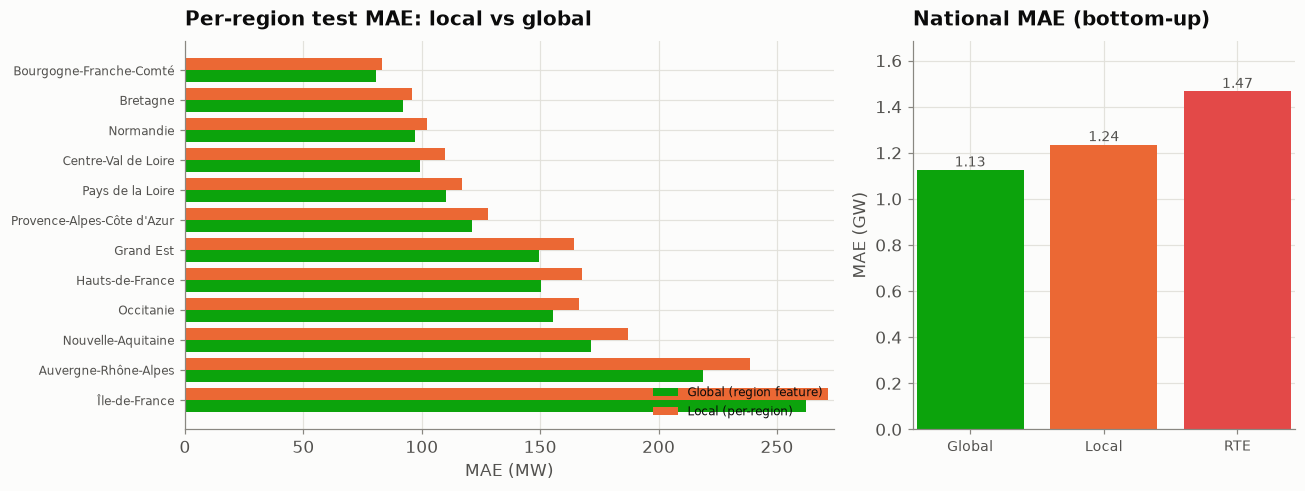

In [14]:
# Plot: per-region MAE (local vs global) and the national bottom-up MAE
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.7, 1]})
pr = per_region.sort_values("global_MAE")
yk = np.arange(len(pr)); hh = 0.4
axes[0].barh(yk + hh/2, pr["global_MAE"].values, height=hh, color=PALETTE["green"], label="Global (region feature)")
axes[0].barh(yk - hh/2, pr["local_MAE"].values,  height=hh, color=PALETTE["orange"], label="Local (per-region)")
axes[0].set_yticks(yk); axes[0].set_yticklabels(pr.index, fontsize=8); axes[0].invert_yaxis()
axes[0].legend(fontsize=8, loc="lower right")
titled(axes[0], "Per-region test MAE: local vs global", xlabel="MAE (MW)")

order = ["Global (region feature)", "Local (per-region)", "RTE (benchmark)"]
vals = [nat_cmp.loc[o, "national_MAE"] / 1000 for o in order]
axes[1].bar(range(3), vals, color=[PALETTE["green"], PALETTE["orange"], PALETTE["red"]])
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(["Global", "Local", "RTE"], fontsize=9)
for i, v in enumerate(vals):
    axes[1].text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=9, color=PALETTE["ink2"])
axes[1].set_ylim(0, max(vals) * 1.15)
titled(axes[1], "National MAE (bottom-up)", ylabel="MAE (GW)")
fig.tight_layout(); fig.savefig(FIG / "33_local_vs_global.png"); plt.show()

### Per-region forecasts and where the error sits

The 12 small multiples show each region's day-ahead forecast (actual vs global vs local) over one winter week. The error
comparison then ranks regions two ways: by **absolute** MAE (MW, which tracks how big a region is) and by **relative**
MAPE (%, which is size-adjusted and shows which regions are intrinsically hardest).

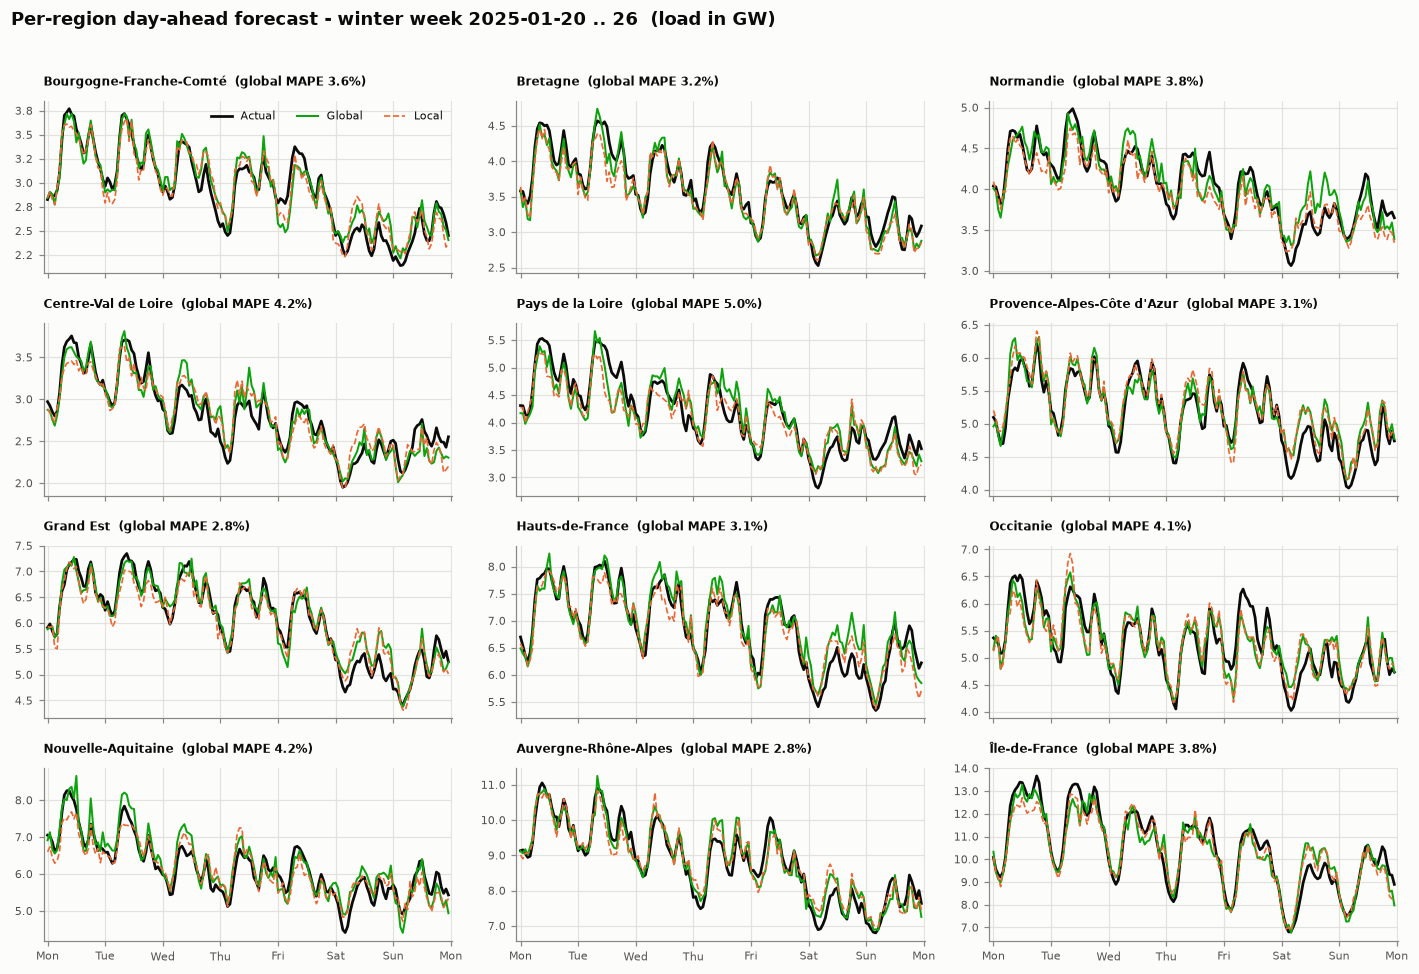

In [15]:
# Per-region day-ahead forecast - example winter week (Actual vs Global vs Local)
start = pd.Timestamp("2025-01-20", tz="UTC"); end = pd.Timestamp("2025-01-26 23:00", tz="UTC")
sub = cmp[(cmp["datetime_utc"] >= start) & (cmp["datetime_utc"] <= end)]
regions_sorted = per_region.index.tolist()                      # ordered by global MAE (easiest -> hardest)
fig, axes = plt.subplots(4, 3, figsize=(13, 9), sharex=True)
for ax, rname in zip(axes.ravel(), regions_sorted):
    d = sub[sub["region"] == rname].sort_values("datetime_utc")
    ax.plot(d["datetime_utc"], d["actual"], color=PALETTE["ink"], lw=1.8, label="Actual")
    ax.plot(d["datetime_utc"], d["glob"], color=PALETTE["green"], lw=1.3, label="Global")
    ax.plot(d["datetime_utc"], d["loc"], color=PALETTE["orange"], lw=1.1, ls="--", label="Local")
    ax.yaxis.set_major_formatter(gw1_fmt)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))
    mape = (np.abs(d["actual"] - d["glob"]) / d["actual"]).mean() * 100
    ax.set_title(f"{rname}  (global MAPE {mape:.1f}%)", loc="left", fontsize=8, fontweight="bold")
    ax.tick_params(labelsize=7); ax.margins(x=0.01)
axes[0, 0].legend(fontsize=7, loc="upper right", ncol=3)
fig.suptitle("Per-region day-ahead forecast - winter week 2025-01-20 .. 26  (load in GW)",
             fontsize=12, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.97]); fig.savefig(FIG / "35_region_forecasts.png"); plt.show()

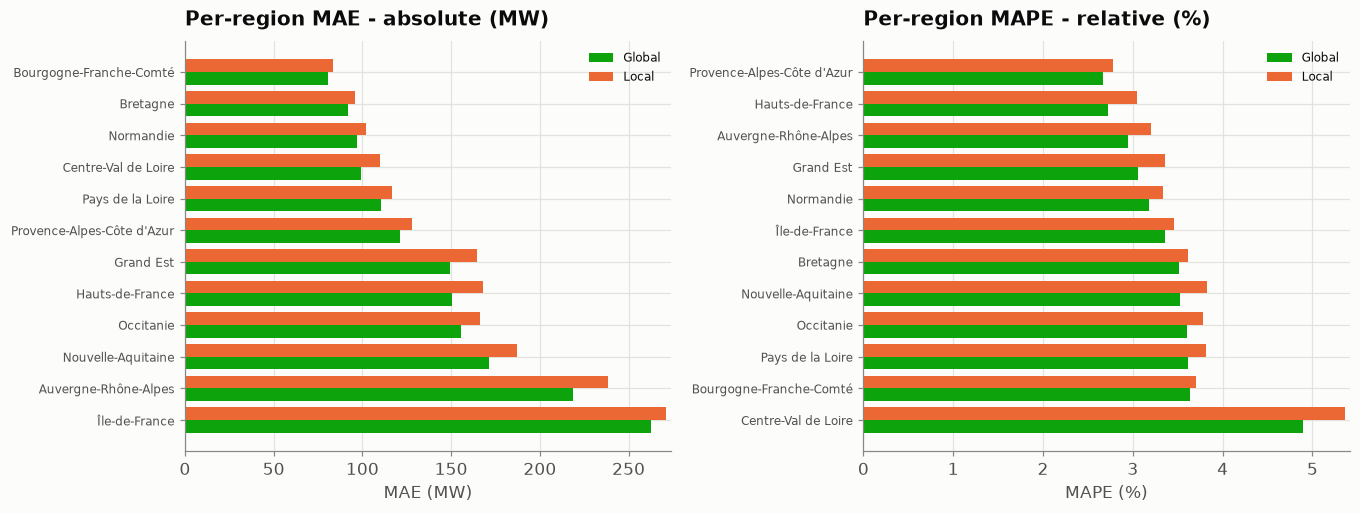

Per-region error, global model (sorted by MAPE):
                            glob_MAE  glob_MAPE
region                                         
Provence-Alpes-Côte d'Azur   121.370      2.660
Hauts-de-France              150.260      2.720
Auvergne-Rhône-Alpes         218.740      2.950
Grand Est                    149.450      3.060
Normandie                     97.210      3.180
Île-de-France                262.370      3.360
Bretagne                      91.990      3.510
Nouvelle-Aquitaine           171.290      3.530
Occitanie                    155.470      3.600
Pays de la Loire             110.240      3.620
Bourgogne-Franche-Comté       80.480      3.630
Centre-Val de Loire           99.120      4.900


In [16]:
# Regional error comparison: absolute (MAE, MW) and relative (MAPE, %), global vs local
err = cmp.groupby("region").apply(lambda d: pd.Series({
    "glob_MAE":  mae(d["actual"], d["glob"]),
    "loc_MAE":   mae(d["actual"], d["loc"]),
    "glob_MAPE": (np.abs(d["actual"] - d["glob"]) / d["actual"]).mean() * 100,
    "loc_MAPE":  (np.abs(d["actual"] - d["loc"]) / d["actual"]).mean() * 100,
}))
hh = 0.4
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
e1 = err.sort_values("glob_MAE"); y1 = np.arange(len(e1))
axes[0].barh(y1 + hh/2, e1["glob_MAE"].values, height=hh, color=PALETTE["green"], label="Global")
axes[0].barh(y1 - hh/2, e1["loc_MAE"].values,  height=hh, color=PALETTE["orange"], label="Local")
axes[0].set_yticks(y1); axes[0].set_yticklabels(e1.index, fontsize=8); axes[0].invert_yaxis(); axes[0].legend(fontsize=8)
titled(axes[0], "Per-region MAE - absolute (MW)", xlabel="MAE (MW)")
e2 = err.sort_values("glob_MAPE"); y2 = np.arange(len(e2))
axes[1].barh(y2 + hh/2, e2["glob_MAPE"].values, height=hh, color=PALETTE["green"], label="Global")
axes[1].barh(y2 - hh/2, e2["loc_MAPE"].values,  height=hh, color=PALETTE["orange"], label="Local")
axes[1].set_yticks(y2); axes[1].set_yticklabels(e2.index, fontsize=8); axes[1].invert_yaxis(); axes[1].legend(fontsize=8)
titled(axes[1], "Per-region MAPE - relative (%)", xlabel="MAPE (%)")
fig.tight_layout(); fig.savefig(FIG / "36_region_error_comparison.png"); plt.show()
print("Per-region error, global model (sorted by MAPE):")
print(err.sort_values("glob_MAPE")[["glob_MAE", "glob_MAPE"]].round(2).to_string())

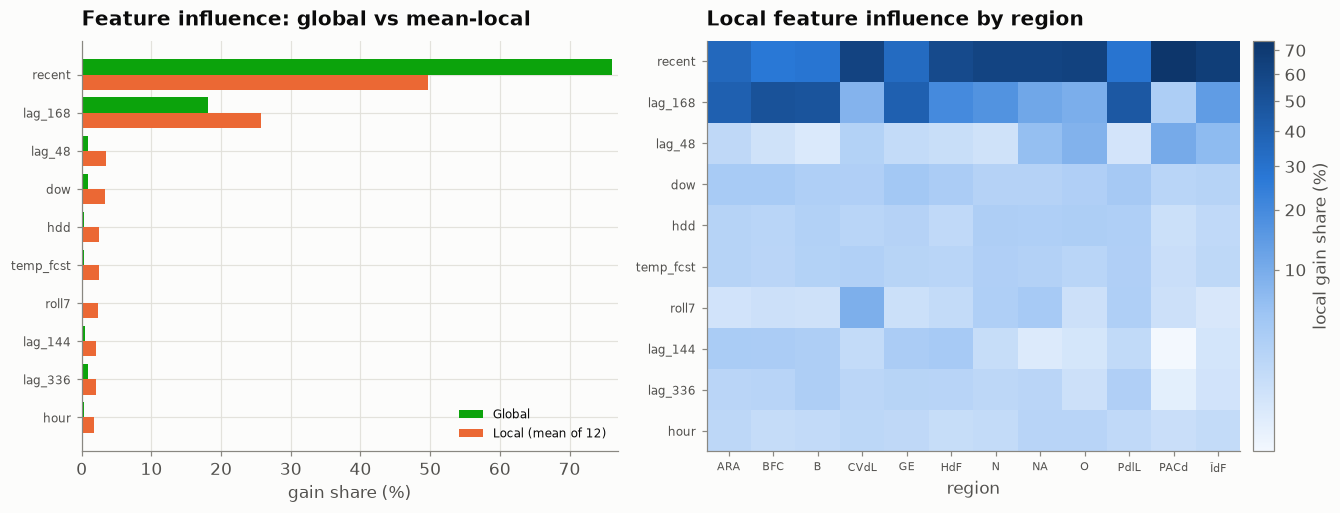

In [17]:
# Feature influence: global vs mean-local (gain %), and the region-by-region pattern
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
BLUE_CMAP = LinearSegmentedColormap.from_list("b", ["#f3f8fe", "#9ec5f4", "#2a78d6", "#0d366b"])

glob_g = pd.Series(models[best].booster_.feature_importance("gain"), index=Xall.columns)
glob_gpct = glob_g / glob_g.sum() * 100
loc_gpct = pd.DataFrame({r: local_gain[r] / local_gain[r].sum() * 100 for r in regions})  # feature x region
mean_loc = loc_gpct.mean(axis=1)

shared = [c for c in Xall.columns if not c.startswith("reg_")]                       # locals have no region id
top = (pd.concat([glob_gpct.reindex(shared), mean_loc.reindex(shared)], axis=1).max(axis=1)
       .sort_values(ascending=False).head(10).index.tolist())
acro = {r: "".join(w[0] for w in r.replace("-", " ").split()) for r in regions}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
yk = np.arange(len(top))[::-1]; hh = 0.4
axes[0].barh(yk + hh/2, glob_gpct.reindex(top).values, height=hh, color=PALETTE["green"], label="Global")
axes[0].barh(yk - hh/2, mean_loc.reindex(top).values, height=hh, color=PALETTE["orange"], label="Local (mean of 12)")
axes[0].set_yticks(yk); axes[0].set_yticklabels(top, fontsize=8); axes[0].legend(fontsize=8)
titled(axes[0], "Feature influence: global vs mean-local", xlabel="gain share (%)")

H = loc_gpct.reindex(top)[regions]
im = axes[1].imshow(H.values, aspect="auto", cmap=BLUE_CMAP, norm=PowerNorm(gamma=0.4))
axes[1].set_yticks(range(len(top))); axes[1].set_yticklabels(top, fontsize=8)
axes[1].set_xticks(range(len(regions))); axes[1].set_xticklabels([acro[r] for r in regions], fontsize=7)
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], pad=0.02).set_label("local gain share (%)", color=PALETTE["ink2"])
titled(axes[1], "Local feature influence by region", xlabel="region")
fig.tight_layout(); fig.savefig(FIG / "34_feature_influence_local_global.png"); plt.show()

**Local vs global - the verdict.** The **global model wins across the board**. It has lower test MAE in **all 12 regions**
(mean regional MAE **142 vs 153 MW**), and its bottom-up national forecast beats the local ensemble **1.13 vs 1.24 GW**
(Wilcoxon p = 3e-09). Both still beat RTE (1.47 GW; local vs RTE p = 1e-13, global vs RTE p = 6e-26) - so even separate
per-region models are a real improvement; the global model is simply the better of the two.

**Why global wins here.** Pooling all 12 regions gives the model ~12x more training rows and lets it borrow shape across
regions that behave alike; with only **two years** of regional history a per-region model is data-starved and overfits its
own noise. The gap is widest exactly where a region is largest / most volatile (Auvergne-Rhône-Alpes +20 MW,
Hauts-de-France +18, Nouvelle-Aquitaine +16) and smallest for the calmest (Bourgogne-Franche-Comté +3).

**Reading the per-region errors.** Absolute MAE tracks region *size* - Île-de-France (262 MW), Auvergne-Rhône-Alpes (219) and Nouvelle-Aquitaine (171) lead it simply because they are the biggest - so the size-adjusted **MAPE** is the fairer lens, and it reorders the ranking: the forecast is **tightest in Provence-Alpes-Côte d'Azur (2.7%) and Hauts-de-France (2.7%)** and **hardest in Centre-Val de Loire (4.9%)**, a small region whose load is noisiest relative to its level. In the example-week small multiples the global (green) and local (dashed orange) tracks nearly overlap, with the gap opening mainly on the daily peaks.

**How their feature use differs.** Both lean on the same two drivers - the cutoff-safe **recent** 24/48 value and **last
week** (`lag_168`) - but the global model concentrates far harder on them (**recent 76% / lag_168 18%** of gain) while the
local models **spread influence** across more signals (recent 50% / lag_168 26%, with weather and weekday each climbing to
~2-3%). Data-starved local models must rely on weaker features, which is part of why they generalise worse. The regional
heatmap exposes heterogeneity the global model smooths over: **weather matters most on the Atlantic west** (Pays de la Loire,
Normandie, Nouvelle-Aquitaine ~6.6% of local gain) and **least in Provence-Alpes-Côte d'Azur (3.0%) and Île-de-France
(4.0%)** - mild-Mediterranean and dense-urban loads are driven more by routine than by temperature.

**Takeaway.** For this dataset the **global regional model with region as a feature is the better design** - more accurate
everywhere, more data-efficient, and one model to maintain instead of twelve. Local models stay useful as a *diagnostic*
(they reveal per-region weather sensitivity) and would only become competitive with substantially more history per region.

## 7 - Summary

**Design.** A single **global regional** ML model (region as a feature) predicts each of the 12 regions; summing
them gives a **bottom-up national** day-ahead forecast. All features respect the 12:00 cutoff: safe demand lags
(>= 48h) + the verified hybrid 24/48 recent value, a 7-day level, **noised** tomorrow-temperature + degree-days,
and calendar incl. **holiday** and **season**.

**Benchmark.** Decision Tree < Random Forest < RTE < XGBoost < LightGBM. The bottom-up **LightGBM beats RTE** on
2025-2026 - national MAE ~1.13 vs ~1.47 GW (**~23% lower**), Wilcoxon p ~ 1e-25 - the first model to answer the
manager's Q1 affirmatively. A single Decision Tree and the Random Forest stay above RTE.

**What the model leans on.** Feature importances are led by the **7-day demand level** and the **recent/safe lags**,
then **calendar** (weekday, hour, month) and **weather** (yesterday's temp, tomorrow's noised temp, degree-days) -
exactly the physical drivers, with region / holiday / season refining the level. No leakage-flavoured feature.

**Local vs global (Section 6).** Training a *separate* LightGBM per region (**local**) loses to the single **global** model in **all 12 regions** and nationally (**1.24 vs 1.13 GW**, Wilcoxon p = 3e-09); both still beat RTE. With only two years of regional history, pooling the data and passing region as a feature is more accurate and simpler to run. Local models spread importance onto weaker features (weather/weekday) and reveal real regional weather sensitivity (strongest on the Atlantic west, weakest in PACA / Ile-de-France), but generalise worse.

**Caveats (honest, and they matter for the grade).** The ~23% edge **partly rests on an idealised i.i.d. noised
weather input** - a realistic correlated forecast error would shrink it; the split is a single chronological holdout
(walk-forward is the gold standard, TP04 Part C); and training is limited to the 2023-2024 regional era (no
COVID/crisis regimes).

**Next.** Fold these ML forecasts and the Notebook-2 ARIMA into a final rolling-origin validation with
**uncertainty intervals** (quantile models) and the deployment recommendation.